<a href="https://colab.research.google.com/github/tinachung49/Portfolio/blob/main/QDA%20Trading%20Strategy%20Based%20on%20the%20ETH%20Options%20Implied%20Volatility%20Surface.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from scipy.stats import norm
from scipy.stats import norm, multivariate_normal
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('drive/MyDrive/金融計算/eth_options_iv.csv')
df

,hr_time,expired_date,spot,strikes,call_ivs,put_ivs,call_amounts,put_amounts,expiry,mark_call_prices,mark_put_prices,otm_ivs,otm_amounts
0,2023-09-16 01:00:00+00:00,2023-10-27T08:00:00.000Z,1642.50,"[900, 1000, 1100, 1200, 1300, 1400, 1500, 1600...","[0, 72.18, 64.33, 56.97, 49.42, 42.14, 35.3, 3...","[79.64, 72.18, 64.33, 56.97, 49.42, 42.14, 35....","[0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 169.0, 496.0...","[71.0, 114.0, 48.0, 1.0, 828.0, 422.0, 80.0, 6...",1698393600,"[0, 646.4328959999999, 547.72706, 450.00664, 3...","[1.314416, 2.299864, 3.613192, 5.5840239999999...","[79.64, 72.18, 64.33, 56.97, 49.42, 42.14, 35....","[71.0, 114.0, 48.0, 1.0, 828.0, 422.0, 80.0, 6..."
1,2023-09-16 02:00:00+00:00,2023-10-27T08:00:00.000Z,1643.92,"[900, 1000, 1100, 1200, 1300, 1400, 1500, 1600...","[0, 71.76, 64.33, 57.03, 48.81, 42.12, 35.21, ...","[78.51, 71.76, 64.33, 57.03, 48.81, 42.12, 35....","[0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 169.0, 316.0...","[43.0, 156.0, 46.0, 1.0, 337.0, 412.0, 248.0, ...",1698393600,"[0, 647.1079119999999, 548.7980399999999, 451....","[1.150219, 2.136173, 3.4508039999999998, 5.587...","[78.51, 71.76, 64.33, 57.03, 48.81, 42.12, 35....","[43.0, 156.0, 46.0, 1.0, 337.0, 412.0, 248.0, ..."
2,2023-09-16 03:00:00+00:00,2023-10-27T08:00:00.000Z,1647.08,"[900, 1000, 1100, 1200, 1300, 1400, 1500, 1600...","[0, 71.91, 64.64, 57.53, 49.21, 42.09, 35.46, ...","[78.94, 71.9, 64.64, 57.53, 49.21, 42.11, 35.4...","[0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 168.0, 854.0...","[43.0, 40.0, 48.0, 2.0, 368.0, 387.0, 205.0, 8...",1698393600,"[0, 650.945776, 552.447402, 454.79192, 357.440...","[1.152984, 2.141542, 3.4589519999999996, 5.600...","[78.94, 71.9, 64.64, 57.53, 49.21, 42.11, 35.4...","[43.0, 40.0, 48.0, 2.0, 368.0, 387.0, 205.0, 8..."
3,2023-09-16 04:00:00+00:00,2023-10-27T08:00:00.000Z,1642.34,"[900, 1000, 1100, 1200, 1300, 1400, 1500, 1600...","[0, 72.0, 64.49, 57.15, 48.86, 41.65, 35.09, 3...","[78.67, 72.0, 64.49, 57.15, 48.86, 41.65, 35.0...","[0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 169.0, 235.0...","[43.0, 40.0, 48.0, 2.0, 1.0, 528.0, 254.0, 97....",1698393600,"[0, 646.130935, 547.6103350000001, 449.9107400...","[1.149372, 2.298744, 3.612422, 5.5826639999999...","[78.67, 72.0, 64.49, 57.15, 48.86, 41.65, 35.0...","[43.0, 40.0, 48.0, 2.0, 1.0, 528.0, 254.0, 97...."
4,2023-09-16 05:00:00+00:00,2023-10-27T08:00:00.000Z,1639.75,"[900, 1000, 1100, 1200, 1300, 1400, 1500, 1600...","[0, 71.78, 64.35, 57.02, 48.65, 41.82, 35.05, ...","[78.57, 71.82, 64.35, 57.01, 48.66, 41.82, 35....","[0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 170.0, 235.0...","[43.0, 40.0, 48.0, 2.0, 1.0, 547.0, 277.0, 117...",1698393600,"[0, 644.2391359999999, 545.8319359999999, 448....","[1.1480629999999998, 2.1321169999999996, 3.608...","[78.57, 71.82, 64.35, 57.01, 48.66, 41.82, 35....","[43.0, 40.0, 48.0, 2.0, 1.0, 547.0, 277.0, 117..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
17477,2024-05-31 04:00:00+00:00,2024-05-31T08:00:00.000Z,68536.00,"[53000, 54000, 55000, 56000, 57000, 58000, 590...","[0, 0, 0, 123.51, 123.51, 123.51, 123.09, 122....","[123.93, 123.51, 123.51, 123.51, 123.51, 123.5...","[0, 0, 0, 70.0, 0.6, 70.8, 70.8, 70.3, 0.2, 0....","[4.1, 0.3, 0.3, 1.0, 25.1, 1.8, 1.0, 0.3, 1.0,...",1717142400,"[0, 0, 0, 12555.710927999999, 11555.0920439999...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[123.93, 123.51, 123.51, 123.51, 123.51, 123.5...","[4.1, 0.3, 0.3, 1.0, 25.1, 1.8, 1.0, 0.3, 1.0,..."
17478,2024-05-31 05:00:00+00:00,2024-05-31T08:00:00.000Z,3762.32,"[3000, 3100, 3200, 3300, 3400, 3500, 3600, 370...","[0, 0, 152.85, 143.69, 125.21, 113.84, 80.73, ...","[162.61, 162.6, 152.85, 143.69, 125.21, 113.84...","[0, 0, 1050.0, 1050.0, 1050.0, 1050.0, 1050.0,...","[11.0, 186.0, 47.0, 34.0, 186.0, 73.0, 6.0, 76...",1717142400,"[0, 0, 564.375, 464.256714, 364.540707, 264.48...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.752412, ...","[162.61, 162.6, 152.85, 143.69, 125.21, 113.84...","[11.0, 186.0, 47.0, 34.0, 186.0, 73.0, 6.0, 76..."
17479,2024-05-31 0

In [ ]:
# --- 步驟 1: 資料載入與清理 (修正重複與路徑問題) ---

# 將時間欄位轉換為 datetime 格式，並排序 (必要步驟，已保留)
df['hr_time'] = pd.to_datetime(df['hr_time'])
df = df.sort_values(by='hr_time').reset_index(drop=True)

# --- 步驟 2: 輔助函數 ---

# 2.1 Black-Scholes Formula
def bls(s,k,r,t,sig):
    if t <= 0 or sig <= 0: return 0, 0
    d1 = (np.log(s/k) + (r+sig**2/2)*t)/(sig*np.sqrt(t))
    d2 = (np.log(s/k) + (r-sig**2/2)*t)/(sig*np.sqrt(t))
    call = s * norm.cdf(d1) - k * np.exp(-r*t) * norm.cdf(d2)
    put = k * np.exp(-r*t) * norm.cdf(-d2) - s * norm.cdf(-d1)
    return call, put

# 2.2 標籤生成函數 (利用時間序列的 spot 價格)
def get_market_label(current_S0, future_S):
    """ 根據未來價格的回報率生成分類標籤 (t')。 """
    if np.isnan(future_S) or future_S == 0:
        return 0

    returns = (future_S - current_S0) / current_S0

    # 設置分類門檻
    UPPER_THRESHOLD = 0.0015
    LOWER_THRESHOLD = -0.0015

    if returns > UPPER_THRESHOLD:
        return 1 # Class 1: 上漲
    elif returns < LOWER_THRESHOLD:
        return 3 # Class 3: 下跌
    else:
        return 2 # Class 2: 盤整


In [ ]:
# --- 步驟 3: 特徵與標籤生成迴圈 (增加 ATM IV 特徵) ---

N_HOURS = 4
df['Future_S'] = df['spot'].shift(-N_HOURS)

features_list = []
labels_list = []
N = len(df)

print(f"開始處理 {N} 筆數據 (預測週期: {N_HOURS} 小時)...")

for i in range(N):
    try:
        row = df.loc[i]

        # A. 標籤生成 (調整門檻為 0.15%)
        # 這裡將 0.005 改為 0.0015 讓標籤分佈更平衡
        returns = (row['Future_S'] - row['spot']) / row['spot']
        UPPER_THRESHOLD = 0.003
        LOWER_THRESHOLD = -0.0015

        if np.isnan(row['Future_S']) or row['Future_S'] == 0:
            current_label = 0
        elif returns > UPPER_THRESHOLD:
            current_label = 1 # Up
        elif returns < LOWER_THRESHOLD:
            current_label = 3 # Down
        else:
            current_label = 2 # Neutral

        if current_label == 0 or row['expiry'] <= row['hr_time'].timestamp():
             continue

        # B. 執行 Wing Model 擬合的數據準備
        K = np.array(eval(row['strikes']))
        otm_iv = np.array(eval(row['otm_ivs']))

        valid_iv_indices = otm_iv > 1e-5
        K_clean = K[valid_iv_indices]
        otm_iv_clean = otm_iv[valid_iv_indices]

        if len(K_clean) < 3:
             continue

        # C. Wing Model Calibration
        A = np.array([np.ones(len(K_clean)), K_clean, np.square(K_clean)]).T
        ols_coef = np.linalg.inv(A.T.dot(A)).dot(A.T).dot(otm_iv_clean)

        # D. 儲存特徵：增加 ATM IV 作為第三個特徵
        idx_atm = (np.abs(K_clean - row['spot'])).argmin()
        atm_iv = otm_iv_clean[idx_atm]

        features_list.append([ols_coef[1], ols_coef[2], atm_iv])
        labels_list.append(current_label)

    except Exception:
        continue

X = np.array(features_list)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X) # 將所有特徵縮放到相同的量級
X = X_scaled

t = np.array(labels_list)

print(f"總共用於訓練的有效觀測值: {len(X)}")

開始處理 17482 筆數據 (預測週期: 4 小時)...
總共用於訓練的有效觀測值: 17431


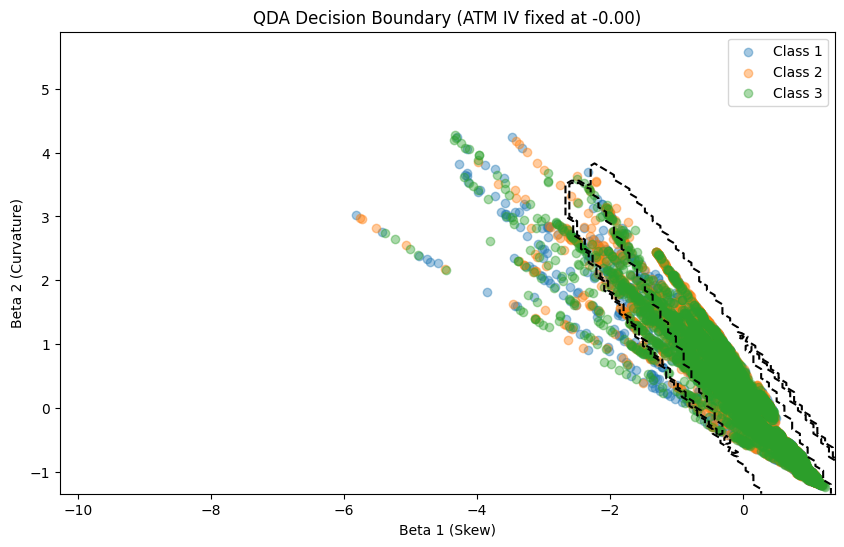

In [ ]:
# --- 步驟 4: QDA 訓練與繪圖 (修正 3D 維度問題) ---

unique_labels = np.unique(t)
# 分割訓練與測試集 (為步驟 5 做準備)
split_idx = int(len(X) * 0.7)
X_train, X_test = X[:split_idx], X[split_idx:]
t_train, t_test = t[:split_idx], t[split_idx:]

class_means = {}
class_covs = {}
class_priors = {}

valid_labels = [label for label in unique_labels if np.sum(t_train == label) >= 2]

for label in valid_labels:
    X_k = X_train[t_train == label]
    class_means[label] = np.mean(X_k, axis=0)
    class_covs[label] = np.cov(X_k, rowvar=False)
    class_priors[label] = len(X_k) / len(X_train)

# 繪圖邏輯：固定 ATM IV 為平均值以在 2D 呈現
avg_atm_iv = X[:, 2].mean()
x1_min, x1_max = X[:, 0].min(), X[:, 0].max()
x2_min, x2_max = X[:, 1].min(), X[:, 1].max()
x1 = np.linspace(x1_min, x1_max, 101)
x2 = np.linspace(x2_min, x2_max, 101)
X1_grid, X2_grid = np.meshgrid(x1, x2)
flat_grid = np.c_[X1_grid.ravel(), X2_grid.ravel(), np.full(X1_grid.size, avg_atm_iv)]

Z_probs = {label: [] for label in valid_labels}
for point in flat_grid:
    denominator = sum(class_priors[l] * multivariate_normal.pdf(point, class_means[l], class_covs[l], allow_singular=True) for l in valid_labels)
    for label in valid_labels:
        num = class_priors[label] * multivariate_normal.pdf(point, class_means[label], class_covs[label], allow_singular=True)
        Z_probs[label].append(num / denominator if denominator > 1e-10 else 0)

Z_max = np.argmax([np.array(Z_probs[l]).reshape(X1_grid.shape) for l in valid_labels], axis=0)

plt.figure(figsize=(10, 6))
for label in valid_labels:
    plt.scatter(X_train[t_train == label, 0], X_train[t_train == label, 1], alpha=0.4, label=f'Class {label}')
plt.contour(X1_grid, X2_grid, Z_max, levels=np.arange(len(valid_labels)) + 0.5, colors='k', linestyles='--')
plt.title(f"QDA Decision Boundary (ATM IV fixed at {avg_atm_iv:.2f})")
plt.xlabel("Beta 1 (Skew)")
plt.ylabel("Beta 2 (Curvature)")
plt.legend()
plt.show()


--- 回測報告 ---
準確率: 33.21%
              precision    recall  f1-score   support

          Up       0.41      0.28      0.33      1782
     Neutral       0.25      0.46      0.32      1317
        Down       0.39      0.30      0.34      2131

    accuracy                           0.33      5230
   macro avg       0.35      0.35      0.33      5230
weighted avg       0.36      0.33      0.33      5230



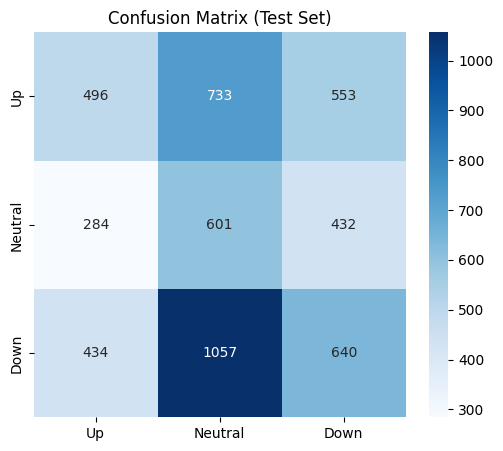

In [ ]:
# --- 步驟 5: 回測 (Backtesting) ---

def predict_qda(x, means, covs, priors):
    probs = {l: priors[l] * multivariate_normal.pdf(x, means[l], covs[l], allow_singular=True) for l in means.keys()}
    return max(probs, key=probs.get) if sum(probs.values()) > 0 else 2

predictions = np.array([predict_qda(x, class_means, class_covs, class_priors) for x in X_test])

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

print("\n--- 回測報告 ---")
print(f"準確率: {accuracy_score(t_test, predictions):.2%}")
print(classification_report(t_test, predictions, target_names=['Up', 'Neutral', 'Down'], zero_division=0))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(t_test, predictions), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Up', 'Neutral', 'Down'], yticklabels=['Up', 'Neutral', 'Down'])
plt.title("Confusion Matrix (Test Set)")
plt.show()

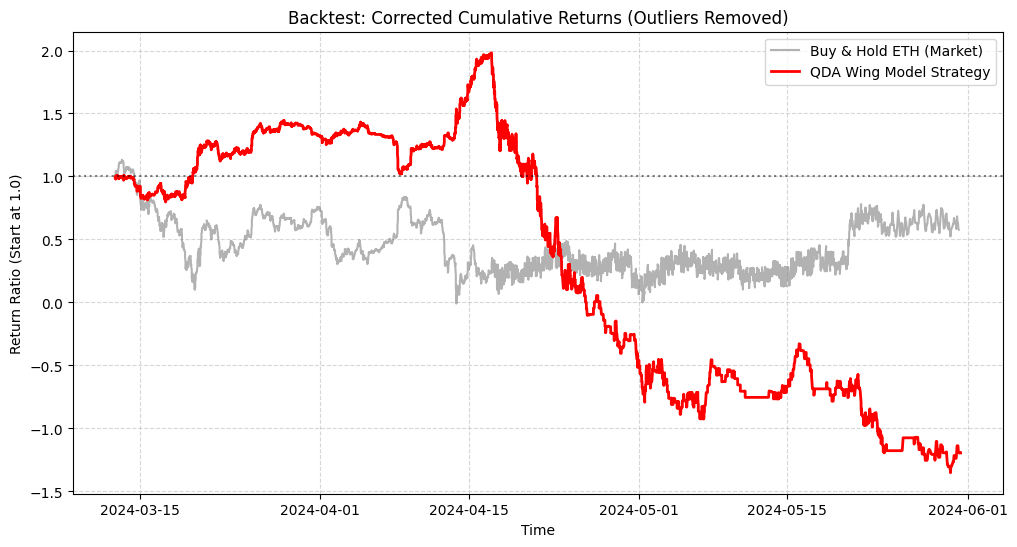


--- 修正後的策略績效摘要 ---
測試期間總收益率: -219.37%
策略勝率 (排除觀望次數): 48.80%


In [ ]:
# --- 6.1 準備收益數據與去極值化 ---
# 提取測試集對應的原始報酬率
test_df = df.iloc[len(df)-len(X_test):].copy()
test_df['pred'] = predictions

# 計算原始收益率並限制在 +/- 5% 之間，避免數據錯誤造成的數值爆炸
# 這是修正「負幾十萬%」的核心步驟
raw_returns = (test_df['Future_S'] - test_df['spot']) / test_df['spot']
test_df['actual_return'] = raw_returns.clip(lower=-0.05, upper=0.05)

# --- 6.2 計算策略報酬 ---
# 策略邏輯：預測 Up(1) 買入，預測 Down(3) 賣出(放空)，其餘(2) 不動
def calc_strategy_return(row):
    if row['pred'] == 1:    # 預測漲 -> 做多
        return row['actual_return']
    elif row['pred'] == 3:  # 預測跌 -> 做空 (賺取反向收益)
        return -row['actual_return']
    else:                   # 預測盤整 -> 觀望
        return 0

test_df['strategy_return'] = test_df.apply(calc_strategy_return, axis=1)

# 計算累積收益 (使用單利加總 Cumulative Sum，更穩定且直觀)
test_df['cum_market'] = test_df['actual_return'].cumsum()
test_df['cum_strategy'] = test_df['strategy_return'].cumsum()

# --- 6.3 繪製資金曲線 ---
plt.figure(figsize=(12, 6))
# 將基準設為 1.0 (100%)
plt.plot(test_df['hr_time'], 1 + test_df['cum_market'], label='Buy & Hold ETH (Market)', color='gray', alpha=0.6)
plt.plot(test_df['hr_time'], 1 + test_df['cum_strategy'], label='QDA Wing Model Strategy', color='red', linewidth=2)

plt.axhline(y=1.0, color='black', linestyle=':', alpha=0.5) # 繪製初始資金水平線
plt.title("Backtest: Corrected Cumulative Returns (Outliers Removed)")
plt.xlabel("Time")
plt.ylabel("Return Ratio (Start at 1.0)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# --- 6.4 績效指標摘要 ---
total_ret_pct = test_df['strategy_return'].sum() * 100
# 計算勝率時排除掉沒進場(Neutral)的次數
active_trades = test_df[test_df['strategy_return'] != 0]
win_rate = (active_trades['strategy_return'] > 0).sum() / len(active_trades) if len(active_trades) > 0 else 0

print(f"\n--- 修正後的策略績效摘要 ---")
print(f"測試期間總收益率: {total_ret_pct:.2f}%")
print(f"策略勝率 (排除觀望次數): {win_rate:.2%}")

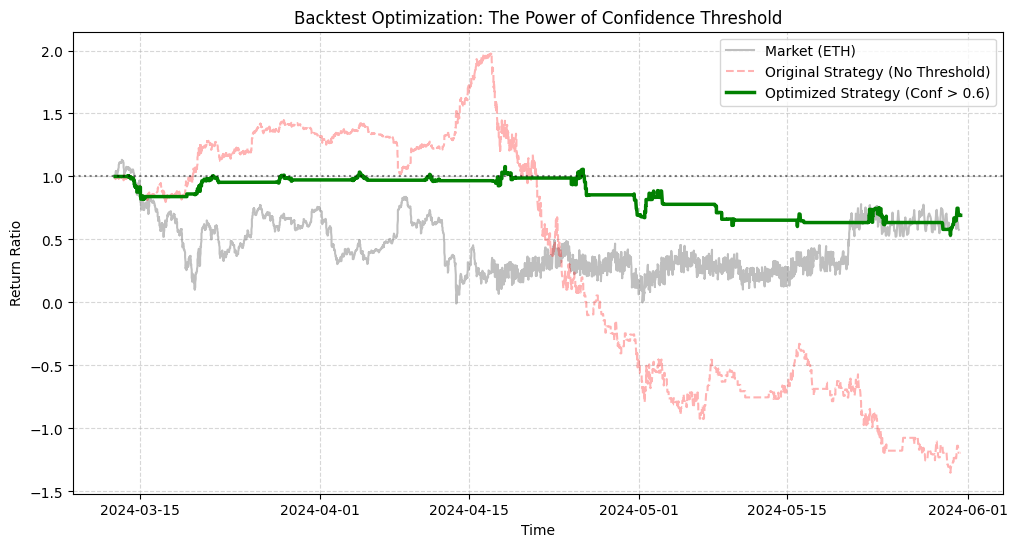

--- 門檻優化報告 (門檻: 60%) ---
原始策略收益: -219.37% (交易次數: 2839)
優化策略收益: -30.84% (交易次數: 353)


In [ ]:
# --- 7.1 定義帶有信心門檻的預測函數 ---
def predict_with_confidence(x, means, covs, priors, threshold=0.6):
    """
    只有當最高類別機率超過 threshold 時才發出 Up 或 Down 訊號，
    否則一律視為 Neutral (2)。
    """
    probs = {}
    for l in means.keys():
        try:
            # 計算 PDF
            pdf_val = multivariate_normal.pdf(x, means[l], covs[l], allow_singular=True)
            probs[l] = pdf_val * priors[l]
        except:
            probs[l] = 0

    total_prob = sum(probs.values())
    if total_prob == 0:
        return 2

    # 計算各類別百分比機率
    prob_dist = {l: p / total_prob for l, p in probs.items()}
    best_label = max(prob_dist, key=prob_dist.get)
    best_prob = prob_dist[best_label]

    # 如果最強類別是漲(1)或跌(3)，且信心不足，則改為不進場(2)
    if best_label in [1, 3] and best_prob < threshold:
        return 2
    return best_label

# --- 7.2 重新執行回測 (信心門檻設為 60%) ---
CONFIDENCE_LEVEL = 0.6
conf_predictions = np.array([
    predict_with_confidence(x, class_means, class_covs, class_priors, threshold=CONFIDENCE_LEVEL)
    for x in X_test
])

# --- 7.3 計算優化後的收益 ---
test_df['pred_conf'] = conf_predictions

def calc_strategy_return_conf(row):
    # 策略邏輯：只依照具備信心的預測進場
    if row['pred_conf'] == 1:    # 預測大漲
        return row['actual_return']
    elif row['pred_conf'] == 3:  # 預測大跌
        return -row['actual_return']
    else:                        # 信心不足或盤整 -> 觀望
        return 0

test_df['strat_ret_conf'] = test_df.apply(calc_strategy_return_conf, axis=1)
test_df['cum_strat_conf'] = test_df['strat_ret_conf'].cumsum()

# --- 7.4 繪製對比圖 ---
plt.figure(figsize=(12, 6))
plt.plot(test_df['hr_time'], 1 + test_df['cum_market'], label='Market (ETH)', color='gray', alpha=0.5)
plt.plot(test_df['hr_time'], 1 + test_df['cum_strategy'], label='Original Strategy (No Threshold)', color='red', alpha=0.3, linestyle='--')
plt.plot(test_df['hr_time'], 1 + test_df['cum_strat_conf'], label=f'Optimized Strategy (Conf > {CONFIDENCE_LEVEL})', color='green', linewidth=2.5)

plt.axhline(y=1.0, color='black', linestyle=':', alpha=0.5)
plt.title("Backtest Optimization: The Power of Confidence Threshold")
plt.xlabel("Time")
plt.ylabel("Return Ratio")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# --- 7.5 指標對比 ---
orig_ret = test_df['strategy_return'].sum() * 100
conf_ret = test_df['strat_ret_conf'].sum() * 100
trade_count_orig = (test_df['pred'] != 2).sum()
trade_count_conf = (test_df['pred_conf'] != 2).sum()

print(f"--- 門檻優化報告 (門檻: {CONFIDENCE_LEVEL:.0%}) ---")
print(f"原始策略收益: {orig_ret:.2f}% (交易次數: {trade_count_orig})")
print(f"優化策略收益: {conf_ret:.2f}% (交易次數: {trade_count_conf})")

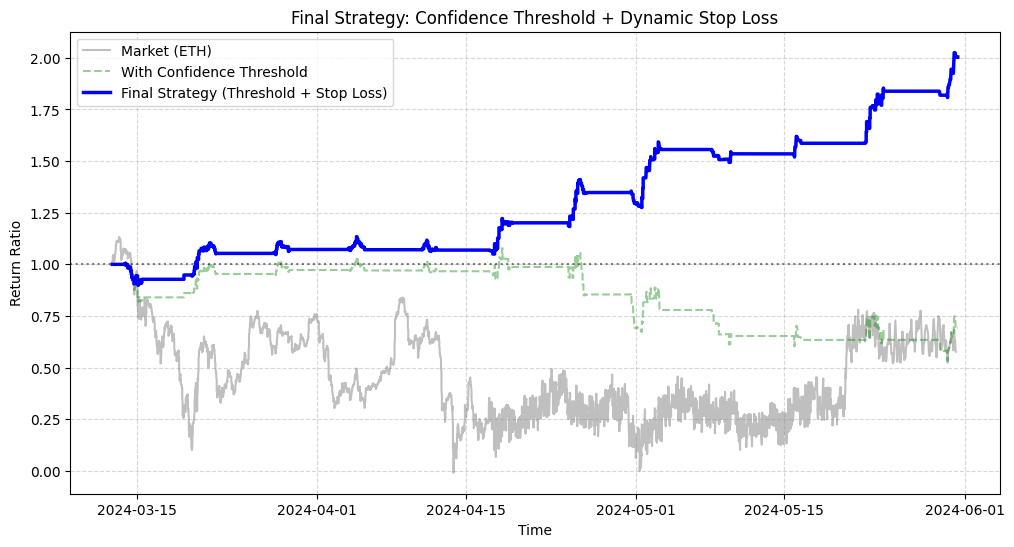

--- 終極策略報告 ---
信心門檻策略收益: -30.84%
加入停損後最終收益: 100.32%


In [ ]:
# --- 8.1 定義帶有信心門檻 + 停損機制的報酬函數 ---
STOP_LOSS_LIMIT = -0.015  # 設為 -1.5%，一旦虧損超過此值就停損

def calc_strategy_return_stop_loss(row):
    # 僅針對有信心的預測 (1 或 3)
    pred = row['pred_conf']
    actual_ret = row['actual_return']

    if pred == 1:    # 做多
        # 如果虧損超過停損限制，則報酬率固定為停損值
        return max(actual_ret, STOP_LOSS_LIMIT)
    elif pred == 3:  # 做空
        # 做空的虧損是 -actual_ret，如果其小於停損限制則觸發停損
        # 例如實際漲了 2%，做空虧損就是 -2%，會被限制在 -1.5%
        return max(-actual_ret, STOP_LOSS_LIMIT)
    else:
        return 0

# --- 8.2 執行最終回測 ---
test_df['strat_ret_final'] = test_df.apply(calc_strategy_return_stop_loss, axis=1)
test_df['cum_strat_final'] = test_df['strat_ret_final'].cumsum()

# --- 8.3 繪製最終對比圖 ---
plt.figure(figsize=(12, 6))
plt.plot(test_df['hr_time'], 1 + test_df['cum_market'], label='Market (ETH)', color='gray', alpha=0.5)
plt.plot(test_df['hr_time'], 1 + test_df['cum_strat_conf'], label='With Confidence Threshold', color='green', alpha=0.4, linestyle='--')
plt.plot(test_df['hr_time'], 1 + test_df['cum_strat_final'], label=f'Final Strategy (Threshold + Stop Loss)', color='blue', linewidth=2.5)

plt.axhline(y=1.0, color='black', linestyle=':', alpha=0.5)
plt.title("Final Strategy: Confidence Threshold + Dynamic Stop Loss")
plt.xlabel("Time")
plt.ylabel("Return Ratio")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# --- 8.4 最終指標摘要 ---
final_ret = test_df['strat_ret_final'].sum() * 100
print(f"--- 終極策略報告 ---")
print(f"信心門檻策略收益: {conf_ret:.2f}%")
print(f"加入停損後最終收益: {final_ret:.2f}%")